# Problemas Inversos: Desborramento de imagens 
**Etapa 2:** Descrição do problema e análise do *dataset*

**Aluno:** Bruno Miyata

Escolhi como projeto a aplicação de problemas inversos em **desborramento de imagens**. Embora existam outros métodos para tal aplicação, me concentrei em reproduzir as publicações de **James Nagy** [2, 3], que utilizam técnicas da disciplina. 

## Referências
[1] BIEMOND, J.; LAGENDIJK, R. L.; MERSEREAU, R. M. Iterative methods for image deblurring. Proceedings of the IEEE, v. 78, n. 5, p. 856–883, 1990. DOI: 10.1109/5.53403.

[2] KAMM, J.; NAGY, J. G. Kronecker product and SVD approximations in image restoration. Linear Algebra and its Applications, v. 284, n. 1–3, p. 177–192, 1998. DOI: 10.1016/S0024-3795(98)10024-1.

[3] NAGY, J. G.; O’LEARY, D. P. Image deblurring: I can see clearly now. Computing in Science & Engineering, v. 5, n. 3, p. 82–84, 2003. DOI: 10.1109/MCISE.2003.1196312.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown as MD

import h5py
from PIL import Image

def bytesTo(x,scint:str='mib'):
    """Converte nbytes em MiB, GiB"""
    scint = scint.lower()
    if scint in ['mib','mb','m']:
        pwr = 20
    elif scint in ['kb','kib','k']:
        pwr = 10
    elif scint in ['gib','gb','g']:
        pwr = 30
    return x/(2**pwr)

def mdisp(arg):
    """Função auxiliar para realizar print com markdown"""
    display(MD(arg))

c:\Users\bruno\.conda\envs\ykk2\lib\site-packages\numpy\_distributor_init.py:30: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\bruno\.conda\envs\ykk2\lib\site-packages\numpy\.libs\libopenblas.FB5AE2TYXYH2IJRDKGDGQ3XBKLKTF43H.gfortran-win_amd64.dll
c:\Users\bruno\.conda\envs\ykk2\lib\site-packages\numpy\.libs\libopenblas64__v0.3.21-gcc_10_3_0.dll
  warnings.warn("loaded more than 1 DLL from .libs:"



## A operação de borramento como uma convolução
Uma **imagem borrada** pode ser representada pela **convolução de uma PSF**(*Point Spread Function*), representada por $\mathbf{P}$, com uma imagem nítida $\mathbf{F}$, que deseja-se determinar
$$
\mathbf{G} = \mathbf P \ast \mathbf{F},
$$
O problema assume que $\mathbf{G}$, $\mathbf{P}$ e $\mathbf{F}$ **possuem as mesmas dimensões**($\sqrt{n}\times \sqrt{n}$).

## A convolução em forma de sistema linear
Em sistema linear, o Kernel(a função que borra a imagem) se torna uma matriz de toeplitz

### A matriz de toeplitz
Matrizes de toeplitz aparecem **naturalmente** ao representar a **convolução** em forma de sistema linear. Essas matrizes apresentam as seguintes características:
- a diagonal principal é **constante**; e
- cada coluna é uma versão **deslocada** de uma sequência.

Para um kernel unidimensional $h = [h_0,h_1,h_2]$, sua representação em matriz de toeplitz é
$$
\mathbf{H} =
\begin{bmatrix}
h_0    & 0      & 0     \\
h_1    & h_0    & 0     \\
h_2    & h_1    & h_0   \\
\end{bmatrix}_{\sqrt{n}\times \sqrt{n}}.
$$
Essa transformação é representada pelo operador $\mathrm{toep}$, em que $\mathbf{H} = \mathrm{toep}(h)$

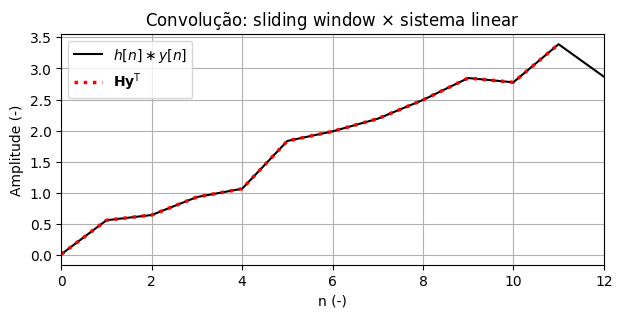

In [ ]:
from scipy.linalg import toeplitz as toep

x = np.random.rand(12) # Sinal de entrada
h = np.random.rand(12) # Kernel de convolução
y_conv = np.convolve(h,x)

#O segundo argumento força convolução linear
H = toep(h,np.zeros(len(x))) #Toep(h), 
y_mmul = H @ x


plt.figure(figsize=(7,3))
plt.plot(y_conv,label='$h[n] \\ast y[n]$',color='black')
plt.plot(y_mmul,label='$\\mathbf{H} \\mathbf{y}^\\mathrm{T}$',linestyle='dotted',linewidth=2.5,color='red')
plt.legend()
plt.grid()
plt.xlim(0,len(x))
plt.xlabel('n (-)');
plt.ylabel('Amplitude (-)')
plt.title('Convolução: sliding window $\\times$ sistema linear');

### E quando o Kernel é 2D?: a matriz BTTB
Quando o kernel é 2D, ele é representado por uma matriz **BTTB**(Bloco Toeplitz com Blocos Toeplitz). Essas matrizes apresentam as características:
- Pode ser particionada em blocos $m\times m$ que são matrizes de toeplitz; e
- Esses blocos formam uma estrutura de toeplitz.

Dessa forma, uma PSF
$$
\mathbf{P} =
\begin{bmatrix}
p_{-1,-1} & p_{-1,0} & p_{-1,1} \\[2pt]
p_{0,-1}  & p_{0,0}  & p_{0,1}  \\[2pt]
p_{1,-1}  & p_{1,0}  & p_{1,1}
\end{bmatrix}_{\sqrt{n}\times\sqrt{n}},
$$
se torna
$$
\mathbf{K} =
\left[\begin{array}{ccc|ccc|ccc}
p_{0,0} & p_{0,-1} & 0 & p_{-1,0} & p_{-1,-1} & 0 & 0 & 0 & 0 \\
p_{0,1} & p_{0,0} & p_{0,-1} & p_{-1,1} & p_{-1,0} & p_{-1,-1} & 0 & 0 & 0 \\
0 & p_{0,1} & p_{0,0} & 0 & p_{-1,1} & p_{-1,0} & 0 & 0 & 0 \\ \hline
p_{1,0} & p_{1,-1} & 0 & p_{0,0} & p_{0,-1} & 0 & p_{-1,0} & p_{-1,-1} & 0 \\
p_{1,1} & p_{1,0} & p_{1,-1} & p_{0,1} & p_{0,0} & p_{0,-1} & p_{-1,1} & p_{-1,0} & p_{-1,-1} \\
0 & p_{1,1} & p_{1,0} & 0 & p_{0,1} & p_{0,0} & 0 & p_{-1,1} & p_{-1,0} \\ \hline
0 & 0 & 0 & p_{1,0} & p_{1,-1} & 0 & p_{0,0} & p_{0,-1} & 0 \\
0 & 0 & 0 & p_{1,1} & p_{1,0} & p_{1,-1} & p_{0,1} & p_{0,0} & p_{0,-1} \\
0 & 0 & 0 & 0 & p_{1,1} & p_{1,0} & 0 & p_{0,1} & p_{0,0}
\end{array}\right]_{{n}\times{n}}.
$$
O operador $\mathrm{toep2}$ realiza essa transformação ($\mathbf{K} = \mathrm{toep2}(\mathbf{P})$)

## O problema inverso
Uma convolução de imagem é representada em forma de sistema linear por
$$
\mathbf{g} = \mathbf{K}\mathbf{f},
$$
em que:
- $\mathbf{g} = \mathrm{vec}(\mathbf{G})$
- $\mathbf{f} = \mathrm{vec}(\mathbf{F})$
- $\mathbf{K} = \mathrm{toep2}(\mathbf{P})$

O operador $\mathrm{vec}$ empilha uma matriz 2D em um vetor coluna

### Mal condicionamento
- $\mathbf{K}$ apresenta número de condição elevado;
- $\mathbf{G}$ é corrompido por ruído; e
- As dimensões de $\mathbf{K}$ crescem quadráticamente com as dimensões de $\mathbf P$.

**O problema é mal posto**

### Poupando espaço na memória
Tipos específicos de PSFs podem ser representadas por meio de um produto de Kronecker, evitando alocação explícita de $\mathbf{K}$
$$
\mathbf K = \mathbf{A} \otimes \mathbf{B} = 
\begin{bmatrix}
    a_{11}\mathbf{B} & \ldots & a_{1m}\mathbf{B}\\
    \vdots & \ddots & \vdots\\
    a_{m1}\mathbf{B}&\ldots & a_{mm}\mathbf{B}
\end{bmatrix}
$$

A SVD de $\mathbf{K}$ pode ser representada pela SVD de $\mathbf{A}$ e $\mathbf{B}$ por meio de
$$
\mathbf{K} = \mathbf{U}\Sigma \mathbf{V}^\mathrm{T} = (\mathbf{U}_A \otimes \mathbf{U}_B) (\Sigma_A \otimes \Sigma_B) (\mathbf{V}_A \otimes \mathbf{V}_B)^\mathrm{T}
$$
em que:
- $\mathbf{A} = \mathbf{U}_A \Sigma_A \mathbf{V}_A^\mathrm{T}$ e 
- $\mathbf{B} = \mathbf{U}_B\Sigma_B \mathbf{V}_B^\mathrm{T}$


## O Dataset: *I can see clearly now* [3]
Nagy [3] apresenta seu método em forma de uma tarefa computacional, em que dado $\mathbf{A}$ e $\mathbf{B}$, deve-se desborrar uma imagem $\mathbf{G}$ com $256\times 256$ pixels.

A natureza da PSF não foi específicada

In [2]:
# Carregando os dados do problema
with h5py.File('Data.hdf5') as f:
    A = f['A'][:]
    B = f['B'][:]

    G = f['G'][:] # Imagem borrada

F = np.array(Image.open('original.jpeg')) #Imagem Original

### Observando $\mathbf{G}$ e $\mathbf{F}$

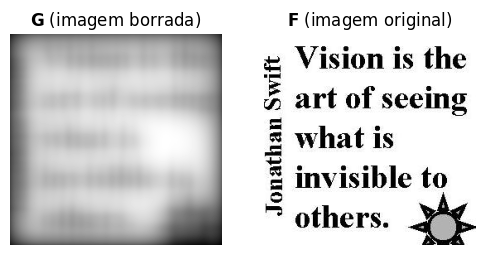

In [ ]:
img_list = [G.T, F]
label_list = [r'$\mathbf{G}$ (imagem borrada)', 
              r'$\mathbf{F}$ (imagem original)']

plt.figure(figsize=(6,3))
for idx, (img,label) in enumerate(zip(img_list,label_list)):
    ax = plt.subplot(1,2,idx+1)
    plt.imshow(img,cmap='gray')
    plt.title(label)
    ax.set_axis_off()

### Qual o tamanho das matrizes?
Nota: $\mathbf{F}$ é considerávelmente mais leve por ser importada de um jpeg (cores são representadas por 8 bits)

In [48]:
mdisp(fr'#### $\mathbf{{G}}$ (Imagem borrada): {G.shape} pixels ({bytesTo(G.nbytes,"mib")} MiB)')
mdisp(fr'#### $\mathbf{{F}}$ (Imagem original): {F.shape} pixels ({bytesTo(F.nbytes,"mib")} MiB)')
mdisp(fr'#### $\mathbf{{A}}$: {A.shape} ({bytesTo(A.nbytes,"mib")} MiB)')
mdisp(fr'#### $\mathbf{{B}}$: {B.shape} ({bytesTo(B.nbytes,"mib")} MiB)')

# E se eu conseguisse alocar K?
K_shape = tuple(np.asarray(A.shape,dtype=float)**2)
K_nbytes = (K_shape[0]*K_shape[1])*np.dtype(A.dtype).itemsize
mdisp(fr'#### $\mathbf{{K}} = \mathbf{{A}} \otimes \mathbf{{B}}$: {K_shape} ({bytesTo(K_nbytes,"gib"):.0f} GiB) (Estimativa)')

#### $\mathbf{G}$ (Imagem borrada): (256, 256) pixels (0.5 MiB)

#### $\mathbf{F}$ (Imagem original): (256, 256) pixels (0.0625 MiB)

#### $\mathbf{A}$: (256, 256) (0.5 MiB)

#### $\mathbf{B}$: (256, 256) (0.5 MiB)

#### $\mathbf{K} = \mathbf{A} \otimes \mathbf{B}$: (65536.0, 65536.0) (32 GiB) (Estimativa)

### Como se parecem $\mathbf{A}$ e $\mathbf{B}$?

Kamm e Nagy [2] mostram que se uma PSF pode ser representada como $\mathbf{P} = \sigma \mathbf{u}\mathbf{v}^\mathrm{T}$ ($\mathrm{rank}(\mathbf{P}) = 1$), as matrizes que compõem $\mathbf{K}$ são dadas por:
- $\mathbf{A} = \mathrm{toep}(\sqrt{\sigma \mathbf{u}})$
- $\mathbf{B} = \mathrm{toep}(\sqrt{\sigma \mathbf{v}})$

Tendo em vista o uso do operador $\mathrm{toep}$, é de se esperar que $\mathbf{A}$ e $\mathbf{B}$ sejam uma linha diagonal descrescente.

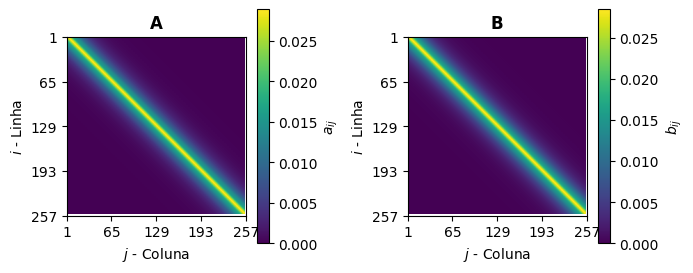

In [71]:
plt.figure(figsize=(7,3))
plt.subplot(1,2,1)
im = plt.imshow(A,origin='upper',extent=[1,A.shape[1]-1,A.shape[0]-1,1])
plt.xlabel('$j$ - Coluna')
plt.ylabel('$i$ - Linha')
plt.colorbar(im,label='$a_{ij}$')
plt.title('$\\mathbf{A}$')
plt.xticks(np.arange(1,258,64))
plt.yticks(np.arange(1,258,64))

plt.subplot(1,2,2)
im = plt.imshow(B,origin='upper',extent=[1,B.shape[1]-1,B.shape[0]-1,1])
plt.xlabel('$j$ - Coluna')
plt.ylabel('$i$ - Linha')
plt.colorbar(im,label='$b_{ij}$')
plt.title('$\\mathbf{B}$')
plt.xticks(np.arange(1,258,64))
plt.yticks(np.arange(1,258,64))
plt.tight_layout()

#### $\mathbf{A}$ e $\mathbf{B}$ são iguais?

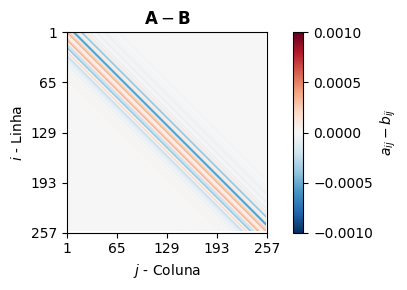

In [73]:
plt.figure(figsize=(6,3))
plt.subplot(111)
im = plt.imshow(A-B,origin='upper',
                extent=[1, B.shape[1]-1,
                        B.shape[0]-1,1],
                cmap='RdBu_r',
                vmin=-1E-3,vmax=1E-3)
plt.xlabel('$j$ - Coluna')
plt.ylabel('$i$ - Linha')
plt.colorbar(im,label='$a_{ij}-b_{ij}$')
plt.title('$\\mathbf{A}-\\mathbf{B}$')
plt.xticks(np.arange(1,258,64))
plt.yticks(np.arange(1,258,64))
plt.tight_layout()